In [2]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
GTE_DIR=os.environ["GTE_DIR"]
from glaciation_time_estimator.auxiliary_func.config_reader import read_config
from glaciation_time_estimator.auxiliary_func.Helper_fun import float_range
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import cmcrameri.cm
from glaciation_time_estimator.auxiliary_func.chunking_data import ChunkLoader



In [3]:
colormap = cmcrameri.cm.lipariS

In [4]:
colormap(2)

(0.639835, 0.384073, 0.40417, 1.0)

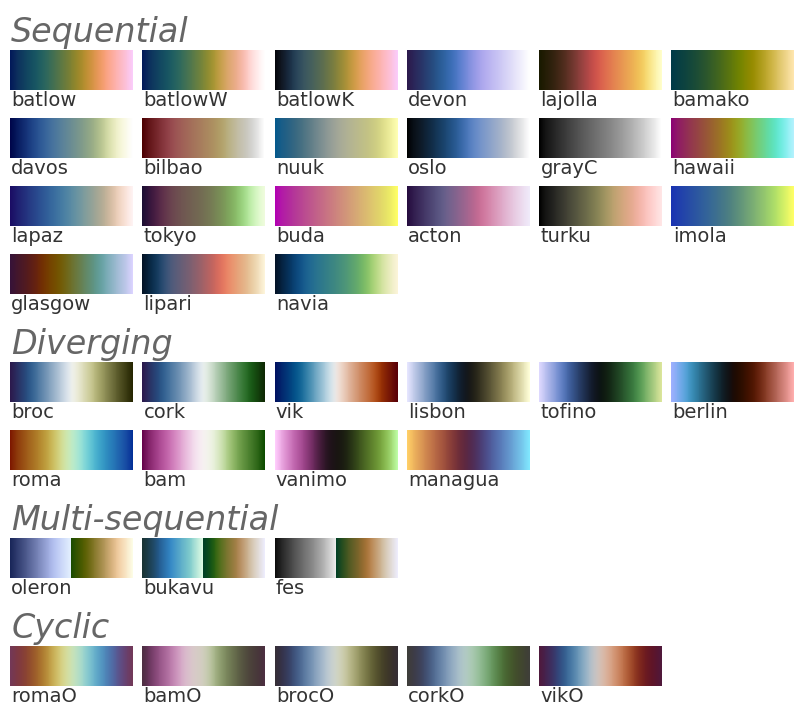

In [5]:
cmcrameri.show_cmaps()  # to load cmcrameri colormaps

In [6]:
config = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/config_n2o.yaml")

In [7]:
glac_threshold=0.4
def calculate_pole_temp_occurance_rate(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk,values='is_glaciating' ,index=["Hemisphere"], columns=["min_temp"], aggfunc='mean')
def calculate_pole_temp_occurance_rate_glac_possible(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk[cloud_chunk.max_water_frac > glac_threshold],values='is_glaciating' ,index=["Hemisphere"], columns=["min_temp"], aggfunc='mean')


In [56]:
import os
import numpy as np
import xarray as xr
import xesmf as xe

# -----------------------------
# 1) Open dataset and detect mask variable
# -----------------------------
fn = "/wolke_scratch/dnikolo/ICON_Data/Nudged_run_cph_13_02/ryan_nudged_test_ctp_2d_ml_20080903T000000Z.nc"
ds = xr.open_dataset(fn)

# Handle possible typo clmast vs ctmask
mask_name = "ctmask" if "ctmask" in ds.data_vars else ("clmast" if "clmast" in ds.data_vars else None)
if mask_name is None:
    raise ValueError("No mask variable found. Expected 'ctmask' (or typo 'clmast').")

# Ensure required vars exist
for v in ["ctp", "ctt"]:
    if v not in ds.data_vars:
        raise ValueError(f"Variable '{v}' not found in dataset.")

# -----------------------------
# 2) Build source lon/lat in degrees
#    Try common ICON names first
# -----------------------------
# Common possibilities
lon_candidates = ["clon", "lon", "longitude"]
lat_candidates = ["clat", "lat", "latitude"]

src_lon_name = next((v for v in lon_candidates if v in ds.variables), None)
src_lat_name = next((v for v in lat_candidates if v in ds.variables), None)

if src_lon_name is None or src_lat_name is None:
    raise ValueError(
        "Could not find source lon/lat coordinates. "
        "Expected one of clon/lon/longitude and clat/lat/latitude."
    )

src_lon = ds[src_lon_name]
src_lat = ds[src_lat_name]

# Convert radians -> degrees if needed (ICON clon/clat are often radians)
def to_degrees_if_radians(da, name):
    vals = da.values
    # Heuristic: radians likely if abs(max) <= ~2*pi
    vmax = np.nanmax(np.abs(vals))
    if vmax <= 6.5:
        print(f"Converting {name} from radians to degrees.")
        return xr.apply_ufunc(np.rad2deg, da)
    else:
        print(f"{name} appears to be in degrees; no conversion.")
        return da

src_lon_deg = to_degrees_if_radians(src_lon, src_lon_name)
src_lat_deg = to_degrees_if_radians(src_lat, src_lat_name)

# Normalize longitude to [-180, 180] (optional but often helpful)
src_lon_deg = ((src_lon_deg + 180) % 360) - 180

# -----------------------------
# 3) Prepare source grid dataset for xESMF
#    For unstructured source, xESMF expects 1D lon/lat + mask
# -----------------------------
# Determine source horizontal dimension from mask
# e.g., "cell", "ncells", etc.
mask_da = ds[mask_name]
if mask_da.ndim != 1:
    # If mask has time or extra dims, take first slice sensibly
    # You can adapt this if needed.
    non_spatial = [d for d in mask_da.dims if d not in src_lon_deg.dims and d not in src_lat_deg.dims]
    if non_spatial:
        sel_dict = {d: 0 for d in non_spatial}
        mask_da = mask_da.isel(sel_dict)
    # squeeze remaining singleton dims
    mask_da = mask_da.squeeze(drop=True)

if mask_da.ndim != 1:
    raise ValueError(
        f"Mask '{mask_name}' must resolve to 1D over source cells. Got dims={mask_da.dims}."
    )

src_dim = mask_da.dims[0]

# Align lon/lat to same dim/order
# If lon/lat are not explicitly on src_dim, try to squeeze/rename
def align_to_src_dim(coord, src_dim):
    c = coord.squeeze(drop=True)
    if c.ndim != 1:
        raise ValueError(f"Coordinate {coord.name} is not 1D after squeeze; dims={coord.dims}")
    if c.dims[0] != src_dim:
        c = c.rename({c.dims[0]: src_dim})
    return c

src_lon_deg = align_to_src_dim(src_lon_deg, src_dim)
src_lat_deg = align_to_src_dim(src_lat_deg, src_dim)

# Build source mask in ESMF convention: 1=valid, 0=masked
src_mask = xr.where(mask_da > 0.5, 1, 0).astype("int32")

ds_in = xr.Dataset(
    data_vars={"mask": (src_dim, src_mask.data)},
    coords={
        "lon": (src_dim, src_lon_deg.data),
        "lat": (src_dim, src_lat_deg.data),
    },
)

# -----------------------------
# 4) Build destination regular lat-lon grid
# -----------------------------
# Choose resolution:
dlat = 0.25
dlon = 0.25

lat_out = np.arange(-90 + dlat / 2, 90, dlat)      # cell centers
lon_out = np.arange(-180 + dlon / 2, 180, dlon)    # cell centers

ds_out = xr.Dataset(coords={"lat": lat_out, "lon": lon_out})

# Optional destination mask (example): keep all cells valid by default
# ds_out["mask"] = xr.DataArray(np.ones((lat_out.size, lon_out.size), dtype="int32"), dims=("lat", "lon"))

# -----------------------------
# 5) Create regridders
# -----------------------------
# For masked geophysical fields, conservative_normed is often robust near coasts/masks.
# For unstructured->regular conservative remap, xESMF/ESMF may require cell bounds on some grids.
# If conservative fails due to missing bounds, use nearest_s2d or bilinear as fallback.

weights_dir = "weights"
os.makedirs(weights_dir, exist_ok=True)

regridder_method_preference = ["conservative_normed", "bilinear", "nearest_s2d"]
regridders = {}

for method in regridder_method_preference:
    wfile = os.path.join(weights_dir, f"icon_to_ll_{method}_{dlat}deg.nc")
    try:
        rg = xe.Regridder(
            ds_in,
            ds_out,
            method=method,
            filename=wfile,
            reuse_weights=os.path.exists(wfile),
            unmapped_to_nan=True,  # important for masked/uncovered targets
        )
        regridders[method] = rg
        print(f"Built regridder: {method}")
    except Exception as e:
        print(f"Could not build {method}: {e}")

if not regridders:
    raise RuntimeError("No regridder could be created. Check grid/bounds compatibility.")

# Pick best available method by preference
for m in regridder_method_preference:
    if m in regridders:
        method_used = m
        regridder = regridders[m]
        break

print(f"Using method: {method_used}")

# -----------------------------
# 6) Apply mask BEFORE remapping data
# -----------------------------
ctp_in = ds["ctp"]
ctt_in = ds["ctt"]

# Align variable dims: ensure source cell dim name matches src_dim
def align_var(v, src_dim):
    # if src_dim not in dims, try rename a single 1D horizontal dim
    if src_dim not in v.dims:
        # heuristically pick dim that matches source size
        candidates = [d for d in v.dims if v.sizes[d] == ds_in.sizes[src_dim]]
        if len(candidates) == 1:
            v = v.rename({candidates[0]: src_dim})
        elif len(candidates) > 1:
            raise ValueError(f"Ambiguous source dim for {v.name}: {candidates}")
        else:
            raise ValueError(f"Could not find source horizontal dim in {v.name}. dims={v.dims}")
    return v

ctp_in = align_var(ctp_in, src_dim)
ctt_in = align_var(ctt_in, src_dim)

# Apply mask on source cells (invalid -> NaN)
valid_bool = src_mask.astype(bool)
ctp_masked = ctp_in.where(valid_bool)
ctt_masked = ctt_in.where(valid_bool)

# -----------------------------
# 7) Remap data fields
# -----------------------------
# xESMF expects dims with lon/lat info from ds_in; for unstructured grids,
# passing DataArray with src_dim works when regridder was built from ds_in.
ctp_out = regridder(ctp_masked)
ctt_out = regridder(ctt_masked)

# Also remap the mask itself for diagnostics
mask_frac_out = regridder(src_mask.astype("float32"))
# "strict" valid target mask threshold (choose threshold to your use case)
# e.g., require at least 50% source support
valid_out = mask_frac_out >= 0.5

# Enforce invalid target cells as NaN
ctp_out = ctp_out.where(valid_out)
ctt_out = ctt_out.where(valid_out)

# -----------------------------
# 8) Save outputs
# -----------------------------
out = xr.Dataset(
    data_vars={
        "ctp": ctp_out,
        "ctt": ctt_out,
        "ctmask_remap_fraction": mask_frac_out,
        "ctmask_target_valid": valid_out.astype("int8"),
    },
    coords={"lat": lat_out, "lon": lon_out},
    attrs={
        "source_file": fn,
        "regridding_method": method_used,
        "note": "ctmask_remap_fraction is remapped source-valid fraction; ctmask_target_valid uses threshold >=0.5",
    },
)

out_fn = "/wolke_scratch/dnikolo/ICON_Data/Nudged_run_cph_13_02/xESMF_regrid.nc"
out.to_netcdf(out_fn)
print(f"Saved: {out_fn}")

Converting clon from radians to degrees.
Converting clat from radians to degrees.
Could not build conservative_normed: buffer is too small for requested array
Could not build bilinear: buffer is too small for requested array
Could not build nearest_s2d: buffer is too small for requested array


RuntimeError: No regridder could be created. Check grid/bounds compatibility.

# 1 Load ddata

In [8]:
glac_low_res_09_01 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_Glaciations_20080901.0000_20080914.2345.parquet")
glac_low_res_09_02 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_Glaciations_20080915.0000_20080930.2345.parquet")
clouds_low_res_09_01 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_clouds_20080901.0000_20080914.2345.parquet")
clouds_low_res_09_02 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_clouds_20080915.0000_20080930.2345.parquet")


In [9]:
clouds_model_offline_09 = pd.read_parquet("/wolke_scratch/dnikolo/ICON_Data/Offline_postproc_out_area/Results/R_Agg_30_clouds_20080901.0015_20080907.2345.parquet")
glac_model_offline_09 = pd.read_parquet("/wolke_scratch/dnikolo/ICON_Data/Offline_postproc_out_area/Results/R_Agg_30_glaciations_20080901.0015_20080907.2345.parquet")


In [10]:
clouds_model_online_09 = pd.read_parquet("/wolke_scratch/dnikolo/ICON_Data/Online_postproc_out/Results/R_Agg_30_clouds_20080901.0015_20080904.2345.parquet")
glac_model_online_09 = pd.read_parquet("/wolke_scratch/dnikolo/ICON_Data/Online_postproc_out/Results/R_Agg_30_glaciations_20080901.0015_20080904.2345.parquet")


In [11]:
loader = ChunkLoader([2008],config,filter=True)

Cloud_fps: {2008: '/wolke_scratch/dnikolo/Final_results/2008_all.parquet'}


In [12]:
clouds_high_res_09 = loader.cloud_chunk[(loader.cloud_chunk.track_start_time>=pd.Timestamp("2008-09-01")) & (loader.cloud_chunk.track_start_time<pd.Timestamp("2008-09-08"))]
glac_high_res_09 = loader.glac_chunk[(loader.glac_chunk.track_start_time>=pd.Timestamp("2008-09-01")) & (loader.glac_chunk.track_start_time<pd.Timestamp("2008-09-08"))]
# clouds_high_res_09 = clouds_high_res_09[clouds_high_res_09["avg_size[km]"]>3e4]

In [13]:
len(clouds_high_res_09)

51088

In [14]:
glac_low_res_09_02.loc[4].ice_frac_hist

array([0.        , 0.39041293, 0.36082023, 0.37872612, 0.42433673,
       0.42242205])

In [15]:
def set_is_glaciating(cloud_df,glac_df):
    cloud_df['is_glaciating'] = (
                    cloud_df.index.isin(
                        glac_df['Cloud_ID']
                    )
                )
set_is_glaciating(clouds_low_res_09_01,glac_low_res_09_01)
set_is_glaciating(clouds_low_res_09_02,glac_low_res_09_02)
set_is_glaciating(clouds_model_offline_09,glac_model_offline_09)
set_is_glaciating(clouds_model_online_09,glac_model_online_09)
clouds_low_res_09 = pd.concat([clouds_low_res_09_01,clouds_low_res_09_02])

In [16]:
def set_hemisphere(cloud_df):
    cloud_df['Hemisphere'] = np.where(cloud_df['avg_lat']>=0,'North','South')
set_hemisphere(clouds_model_offline_09)

In [17]:
(glac_model_offline_09.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.910724
True     0.089276
Name: proportion, dtype: float64

In [18]:
print(glac_model_offline_09.track_length.median())
print(glac_model_offline_09["Time [m]"].median())

0 days 03:30:00
60.0


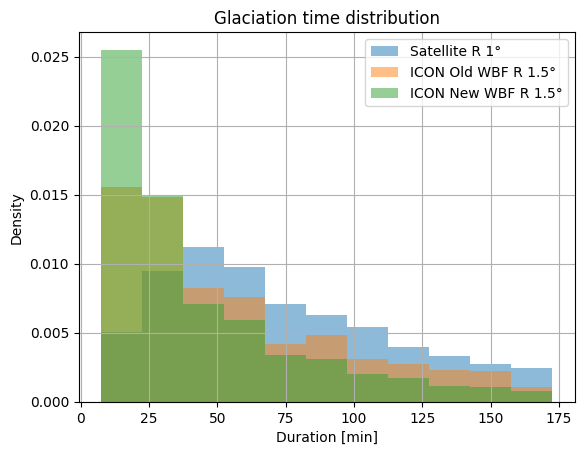

In [19]:
glac_low_res_09_01["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="Satellite R 1°")
glac_model_offline_09["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON Old WBF R 1.5°")
glac_model_online_09["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON New WBF R 1.5°")
plt.title("Glaciation time distribution")
plt.xlabel("Duration [min]")
plt.ylabel("Density")
plt.legend()

In [20]:
glac_low_res_09_01['Magnitude']

0       0.502976
1       0.457451
2       0.405380
3       0.433415
4       0.407823
          ...   
2916    0.558958
2917    0.608115
2918    0.542952
2919    0.407550
2920    0.436192
Name: Magnitude, Length: 2921, dtype: float64

In [21]:
import datetime as dt


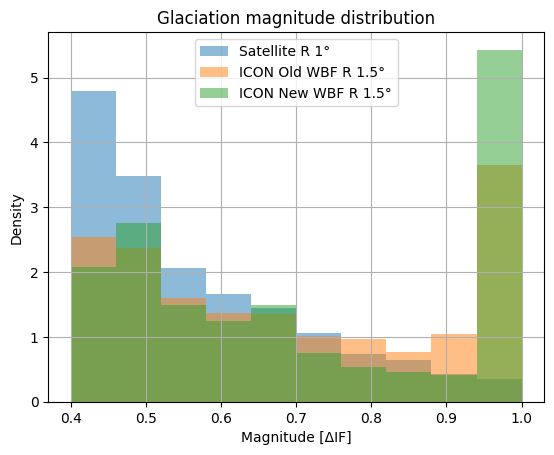

In [22]:

(glac_low_res_09_01["Magnitude"]).hist( alpha=0.5, density=True,label="Satellite R 1°")
# (glac_high_res_09["Magnitude"]).hist( alpha=0.5, density=True,label="Satellite R 0.05°")
(glac_model_offline_09["Magnitude"]).hist( alpha=0.5, density=True,label="ICON Old WBF R 1.5°")
(glac_model_online_09["Magnitude"]).hist( alpha=0.5, density=True,label="ICON New WBF R 1.5°")
plt.title("Glaciation magnitude distribution")
plt.xlabel("Magnitude [ΔIF]")
plt.ylabel("Density")
plt.legend()

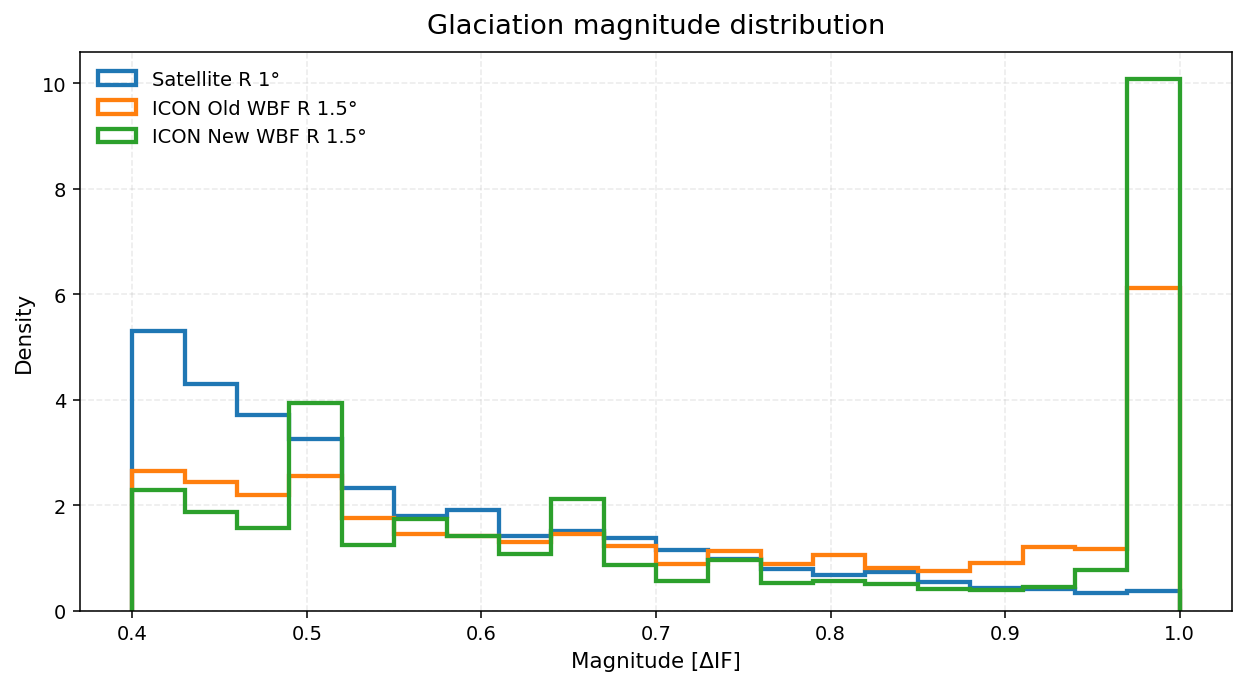

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Optional: cleaner style
plt.style.use("default")  # or "seaborn-v0_8-whitegrid" if available

fig, ax = plt.subplots(figsize=(9, 5), dpi=140)

# Use common bins so curves are directly comparable
all_vals = np.concatenate([
    glac_low_res_09_01["Magnitude"].dropna().values,
    glac_model_offline_09["Magnitude"].dropna().values,
    glac_model_online_09["Magnitude"].dropna().values
])
bins = np.histogram_bin_edges(all_vals, bins=20)

ax.hist(
    glac_low_res_09_01["Magnitude"].dropna(),
    bins=bins, density=True, histtype="step", linewidth=2.2,
    label="Satellite R 1°"
)

# ax.hist(
#     glac_high_res_09["Magnitude"].dropna(),
#     bins=bins, density=True, histtype="step", linewidth=2.2,
#     label="Satellite R 0.05°"
# )

ax.hist(
    glac_model_offline_09["Magnitude"].dropna(),
    bins=bins, density=True, histtype="step", linewidth=2.2,
    label="ICON Old WBF R 1.5°"
)

ax.hist(
    glac_model_online_09["Magnitude"].dropna(),
    bins=bins, density=True, histtype="step", linewidth=2.2,
    label="ICON New WBF R 1.5°"
)

ax.set_title("Glaciation magnitude distribution", fontsize=14, pad=10)
ax.set_xlabel("Magnitude [ΔIF]", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.grid(True, alpha=0.25, linestyle="--")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


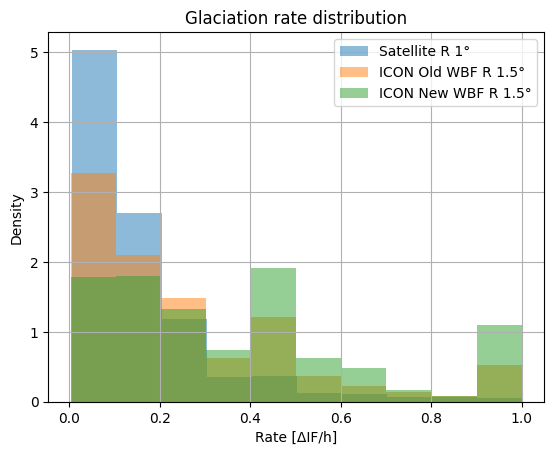

In [24]:
(glac_low_res_09_01["Magnitude"]/(glac_low_res_09_01["Time [m]"]/15)).hist( alpha=0.5, density=True,label="Satellite R 1°")
# glac_model_offline_09["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 1.5°")
(glac_model_offline_09["Magnitude"]/(glac_model_offline_09["Time [m]"]/15)).hist( alpha=0.5, density=True,label="ICON Old WBF R 1.5°")
(glac_model_online_09["Magnitude"]/(glac_model_online_09["Time [m]"]/15)).hist( alpha=0.5, density=True,label="ICON New WBF R 1.5°")

plt.title("Glaciation rate distribution")
plt.xlabel("Rate [ΔIF/h]")
plt.ylabel("Density")
plt.legend()


In [25]:
from scipy.signal import savgol_filter

def noise_filter_4(row, w=4, order=2):
    IF_hist = np.array(row['ice_frac_hist'])
    return savgol_filter(IF_hist, w, order)

In [26]:
se_sum=0
sample_count=0
for i, row in glac_low_res_09_01.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.059986265718067575


In [27]:
se_sum=0
sample_count=0
for i, row in glac_model_offline_09.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.09904602915537154


In [28]:
se_sum=0
sample_count=0
for i, row in glac_model_online_09.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.10703259156034414


In [29]:
(glac_low_res_09_01["Time [m]"]==15).value_counts()

Time [m]
False    2735
True      186
Name: count, dtype: int64

In [30]:
print(glac_low_res_09_01.track_length.median())
print(glac_low_res_09_01["Time [m]"].median())
print(glac_low_res_09_01["Time [m]"].std())

0 days 02:45:00
75.0
124.5260021826595


In [31]:
print(glac_high_res_09.track_length.median())
print(glac_high_res_09["Time [m]"].median())

0 days 01:45:00
60.0


In [32]:
clouds_model_offline_09

,tracknumber,is_large_pix_cloud,is_cot_valid_cloud,is_ctp_valid_cloud,is_liq,is_mix,is_ice,max_water_frac,max_ice_fraction,avg_size[km],...,ctt_std_hist,lat_hist,lon_hist,size_hist_km,min_temp,max_temp,pole,Hemisphere,Lifetime [h],is_glaciating
0,1,True,False,False,True,True,False,1.000000,0.303393,4.805237e+06,...,[],"[-47.66607065720058, -47.74429837603382, -47.7...","[93.34997348134978, 93.20243163966083, 92.7264...","[5293775.128415372, 5375122.137953374, 5413109...",-6,0,np,South,108.75,False
1,2,True,False,False,True,True,False,0.997660,0.389942,1.327623e+06,...,[],"[-57.737743432854316, -57.82883594868055, -58....","[-94.64363065308765, -95.39302201255907, -94.5...","[3100284.329365269, 3231510.602680752, 2892455...",-6,0,np,South,56.75,False
2,3,True,False,False,True,True,False,0.983381,0.299805,4.328851e+06,...,[],"[54.398729328821894, 55.84649124451093, 53.734...","[73.48741732547627, 80.64106951776924, 64.1245...","[2015032.1402024832, 1431177.4212570237, 28734...",-6,0,np,North,167.50,False
3,4,True,False,False,False,True,False,0.832893,0.767220,2.078373e+06,...,[],"[55.40554500647155, 55.44151738636921, 55.5432...","[-167.35960004725737, -167.44532444363819, -16...","[1885201.6120319841, 1898607.843455801, 181804...",-6,0,np,North,35.25,True
4,5,True,False,False,False,True,False,0.730036,0.739695,1.915530e+06,...,[],"[51.31092706825735, 51.366389605070395, 51.404...","[162.54451835632216, 162.5631168672442, 157.91...","[1960489.8653635832, 1942101.1758079529, 14359...",-6,0,np,North,29.25,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27840,2033,True,False,False,False,False,True,0.000000,1.000000,2.471582e+04,...,[],"[50.0, 50.0, 50.0, 49.23860560622051, 48.5]","[-56.5, -56.5, -55.75, -55.0, -55.0]","[17499.892673716033, 17499.892673716033, 34999...",-36,-30,np,North,1.00,False
27841,2034,True,False,False,False,False,True,0.000000,1.000000,5.166119e+04,...,[],"[38.0, 38.0, 38.0, 37.61937263436205, 37.61937...","[150.5, 150.5, 149.75, 150.88062736563796, 150...","[21453.592766943002, 21453.592766943002, 42907...",-36,-30,np,North,1.00,False
27842,2035,True,False,False,False,False,True,0.000000,1.000000,2.787555e+04,...,[],"[-43.0, -43.0, -43.0, -43.0, -43.0]","[30.499999999999996, 30.499999999999996, 31.24...","[19911.104526581916, 19911.104526581916, 39822...",-36,-30,np,South,1.00,False
27843,2036,True,False,False,False,False,True,0.000000,1.000000,3.162155e+04,...,[],"[-38.5, -38.5, -39.49284411159426, -40.0]","[-32.5, -32.5, -32.996422055797126, -34.0]","[21306.50707030697, 21306.50707030697, 63017.6...",-36,-30,np,South,0.75,False


In [33]:
clouds_low_res_09_01

,tracknumber,is_large_pix_cloud,is_cot_valid_cloud,is_ctp_valid_cloud,is_liq,is_mix,is_ice,max_water_frac,max_ice_fraction,avg_size[km],...,ctt_std_hist,lat_hist,lon_hist,size_hist_km,min_temp,max_temp,pole,Hemisphere,Lifetime [h],is_glaciating
0,1,False,False,False,True,False,False,1.000000,0.003263,214.957317,...,[],"[73.32926169025134, 73.19720530757105, 72.2001...","[14.484552886360618, 12.512737380228453, 15.93...","[81.0, 106.0, 70.0, 97.0, 103.0, 103.0, 99.0, ...",-6,0,np,North,81.75,False
1,2,False,False,False,True,False,False,1.000000,0.004284,31.636364,...,[],"[57.110703587343075, 55.88563478842183, 56.269...","[30.42826902863848, 32.14981660645008, 31.8777...","[61.0, 43.0, 39.0, 40.0, 38.0, 35.0, 37.0, 35....",-6,0,np,North,5.25,False
2,3,False,False,False,True,False,False,1.000000,0.007116,26.178571,...,[],"[53.13224105045552, 52.32199464565207, 52.3659...","[-21.70164988082282, -20.155225533163442, -20....","[29.0, 28.0, 28.0, 30.0, 31.0, 32.0, 34.0, 36....",-6,0,np,North,6.75,False
3,4,False,False,False,True,False,False,1.000000,0.012426,19.680000,...,[],"[57.03739466572234, 56.61150474011621, 56.9043...","[56.88334155430668, 56.867911136131006, 57.013...","[22.0, 21.0, 21.0, 20.0, 19.0, 18.0, 19.0, 17....",-6,0,np,North,6.00,False
4,5,False,False,False,True,False,False,1.000000,0.018136,14.147059,...,[],"[62.68309799203851, 62.452214730738454, 62.421...","[40.31107243364053, 40.2486798731911, 40.75205...","[22.0, 23.0, 19.0, 20.0, 20.0, 19.0, 18.0, 19....",-6,0,np,North,8.25,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123504,10598,False,False,False,False,True,False,0.823912,0.268286,2.000000,...,[],"[-69.4297458794524, -69.4297458794524, -69.429...","[4.759308178062998, 5.77769012926543, 5.268499...","[2.0, 2.0, 3.0, 1.0]",-36,-30,sp,South,0.75,False
123505,10599,False,False,False,False,True,False,0.642717,0.579011,3.000000,...,[],"[-66.9717466785479, -66.9717466785479, -66.971...","[-41.57707060164768, -41.06787962604646, -40.5...","[1.0, 2.0, 3.0, 6.0]",-36,-30,sp,South,0.75,False
123506,10600,False,False,False,False,True,False,0.778602,0.309517,1.000000,...,[],"[-65.74274707809566, -65.74274707809566, -65.7...","[43.96701329935665, 43.96701329935665, 43.9670...","[1.0, 1.0, 1.0, 1.0]",-36,-30,sp,South,0.75,False
123507,10601,False,False,False,False,True,False,0.760408,0.387617,1.250000,...,[],"[-53.45275107357321, -53.45275107357321, -53.4...","[-23.246195480003895, -23.246195480003895, -23...","[1.0, 1.0, 1.0, 2.0]",-36,-30,sp,South,0.75,False


In [34]:
(glac_high_res_09.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.991385
True     0.008615
Name: proportion, dtype: float64

In [35]:
clouds_model_offline_09[(clouds_model_offline_09.avg_lat>30) | (clouds_model_offline_09.avg_lat<-30)]

,tracknumber,is_large_pix_cloud,is_cot_valid_cloud,is_ctp_valid_cloud,is_liq,is_mix,is_ice,max_water_frac,max_ice_fraction,avg_size[km],...,ctt_std_hist,lat_hist,lon_hist,size_hist_km,min_temp,max_temp,pole,Hemisphere,Lifetime [h],is_glaciating
0,1,True,False,False,True,True,False,1.000000,0.303393,4.805237e+06,...,[],"[-47.66607065720058, -47.74429837603382, -47.7...","[93.34997348134978, 93.20243163966083, 92.7264...","[5293775.128415372, 5375122.137953374, 5413109...",-6,0,np,South,108.75,False
1,2,True,False,False,True,True,False,0.997660,0.389942,1.327623e+06,...,[],"[-57.737743432854316, -57.82883594868055, -58....","[-94.64363065308765, -95.39302201255907, -94.5...","[3100284.329365269, 3231510.602680752, 2892455...",-6,0,np,South,56.75,False
2,3,True,False,False,True,True,False,0.983381,0.299805,4.328851e+06,...,[],"[54.398729328821894, 55.84649124451093, 53.734...","[73.48741732547627, 80.64106951776924, 64.1245...","[2015032.1402024832, 1431177.4212570237, 28734...",-6,0,np,North,167.50,False
3,4,True,False,False,False,True,False,0.832893,0.767220,2.078373e+06,...,[],"[55.40554500647155, 55.44151738636921, 55.5432...","[-167.35960004725737, -167.44532444363819, -16...","[1885201.6120319841, 1898607.843455801, 181804...",-6,0,np,North,35.25,True
4,5,True,False,False,False,True,False,0.730036,0.739695,1.915530e+06,...,[],"[51.31092706825735, 51.366389605070395, 51.404...","[162.54451835632216, 162.5631168672442, 157.91...","[1960489.8653635832, 1942101.1758079529, 14359...",-6,0,np,North,29.25,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27840,2033,True,False,False,False,False,True,0.000000,1.000000,2.471582e+04,...,[],"[50.0, 50.0, 50.0, 49.23860560622051, 48.5]","[-56.5, -56.5, -55.75, -55.0, -55.0]","[17499.892673716033, 17499.892673716033, 34999...",-36,-30,np,North,1.00,False
27841,2034,True,False,False,False,False,True,0.000000,1.000000,5.166119e+04,...,[],"[38.0, 38.0, 38.0, 37.61937263436205, 37.61937...","[150.5, 150.5, 149.75, 150.88062736563796, 150...","[21453.592766943002, 21453.592766943002, 42907...",-36,-30,np,North,1.00,False
27842,2035,True,False,False,False,False,True,0.000000,1.000000,2.787555e+04,...,[],"[-43.0, -43.0, -43.0, -43.0, -43.0]","[30.499999999999996, 30.499999999999996, 31.24...","[19911.104526581916, 19911.104526581916, 39822...",-36,-30,np,South,1.00,False
27843,2036,True,False,False,False,False,True,0.000000,1.000000,3.162155e+04,...,[],"[-38.5, -38.5, -39.49284411159426, -40.0]","[-32.5, -32.5, -32.996422055797126, -34.0]","[21306.50707030697, 21306.50707030697, 63017.6...",-36,-30,np,South,0.75,False


In [36]:
colormap(0)

(0.01137, 0.07324, 0.148284, 1.0)

In [37]:
clouds_model_online_09["Hemisphere"] = np.where(
    clouds_model_online_09["avg_lat"] >= 0,
    "North",
    "South"
)

/tmp/ipykernel_26024/1506856206.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])


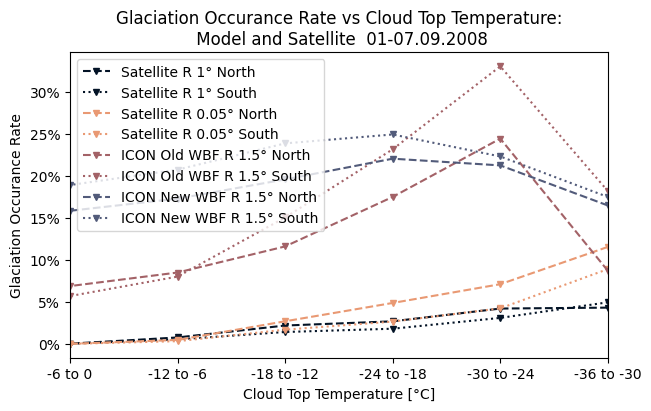

In [38]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
high_res_occ_rate = calculate_pole_temp_occurance_rate((clouds_high_res_09,None,None))
low_res_occ_rate = calculate_pole_temp_occurance_rate((clouds_low_res_09_01,None,None))
model_occ_rate = calculate_pole_temp_occurance_rate((clouds_model_offline_09,None,None))
model_online_occ_rate = calculate_pole_temp_occurance_rate((clouds_model_online_09,None,None))

ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['North'],label='Satellite R 1° North',color=colormap(0),linestyle='dashed',marker='v',markersize=4)
ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['South'],label='Satellite R 1° South',color=colormap(0),linestyle='dotted',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['North'],label='Satellite R 0.05° North',color = colormap(3),linestyle='dashed',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['South'],label='Satellite R 0.05° South',color = colormap(3),linestyle='dotted',marker='v',markersize=4)
ax.plot(model_occ_rate.columns,model_occ_rate.loc['North'],label='ICON Old WBF R 1.5° North',color=colormap(2),linestyle='dashed',marker='v',markersize=4)
ax.plot(model_occ_rate.columns,model_occ_rate.loc['South'],label='ICON Old WBF R 1.5° South',color=colormap(2),linestyle='dotted',marker='v',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['North'],label='ICON New WBF R 1.5° North',color=colormap(4),linestyle='dashed',marker='v',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['South'],label='ICON New WBF R 1.5° South',color=colormap(4),linestyle='dotted',marker='v',markersize=4)

ax.set_xlim(-36,-6)

ax.invert_xaxis()
vals = ax.get_yticks()
ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
ax.set_ylabel('Glaciation Occurance Rate')
ax.legend()
ax.set_xlabel('Cloud Top Temperature [°C]')
ax.set_xticks(np.arange(-36,-6+1,6),labels=[f"{i} to {i+6}" for i in range(-36,0,6)])
ax.set_title('Glaciation Occurance Rate vs Cloud Top Temperature:\n Model and Satellite  01-07.09.2008')
# plt.ylim(0,0.1)
fig.savefig("/wolke_scratch/dnikolo/MSGI/figures/occ_rate_model_vs_satellite_1deg.png",dpi=400)

In [39]:
clouds_low_res_09_01_lim = clouds_low_res_09_01[(clouds_low_res_09_01.track_start_time>=pd.Timestamp("2008-09-01")) & (clouds_low_res_09_01.track_start_time<pd.Timestamp("2008-09-08"))]

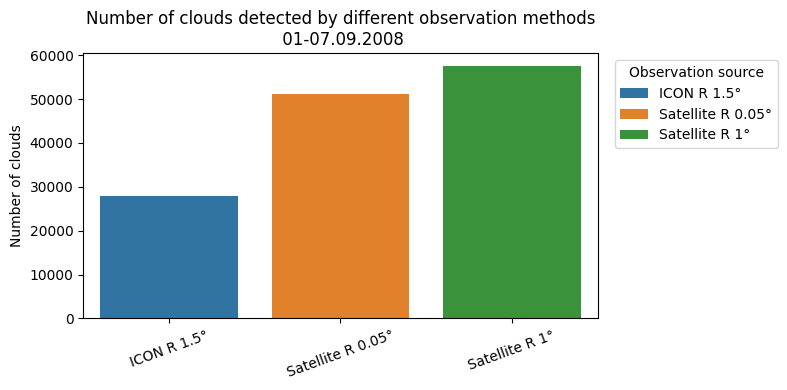

In [40]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Count rows in each dataframe
counts = pd.DataFrame({
    "Observation method": [
        "ICON R 1.5°",
        "Satellite R 0.05°",
        "Satellite R 1°"
        
    ],
    "Num clouds (rows)": [
        len(clouds_model_offline_09),
        len(clouds_high_res_09),
        len(clouds_low_res_09_01_lim)
    ]
})

plt.figure(figsize=(8, 4))
ax = sns.barplot(
    data=counts,
    x="Observation method",
    y="Num clouds (rows)",
    hue="Observation method",      # makes a legend
    dodge=False
)

ax.set_xlabel("")
ax.set_ylabel("Number of clouds")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Observation source", bbox_to_anchor=(1.02, 1), loc="upper left")

# (optional) add value labels on bars
# for container in ax.containers:
#     ax.bar_label(container, fmt="%.0f", padding=3)
ax.set_title("Number of clouds detected by different observation methods\n 01-07.09.2008")
plt.tight_layout()
plt.show()


In [41]:
(clouds_model_offline_09["avg_size[km]"]<0.01e7).value_counts(normalize=True)

avg_size[km]
True     0.886874
False    0.113126
Name: proportion, dtype: float64

In [42]:
import seaborn as sns

Text(0.5, 0, 'Cloud top area [km^2]')

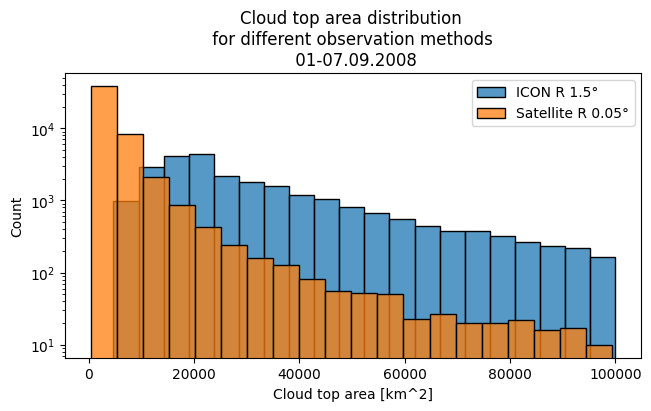

In [43]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
sns.histplot(clouds_model_offline_09[clouds_model_offline_09["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="ICON R 1.5°" )
sns.histplot(clouds_high_res_09[clouds_high_res_09["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="Satellite R 0.05°")
ax.set_title('Cloud top area distribution \n for different observation methods \n 01-07.09.2008')
plt.legend()
ax.set_xlabel('Cloud top area [km^2]')

In [44]:
(clouds_high_res_09["avg_size[km]"]<0.01e7).value_counts(normalize=True)

avg_size[km]
True     0.995968
False    0.004032
Name: proportion, dtype: float64

<Axes: xlabel='avg_size[km]', ylabel='Count'>

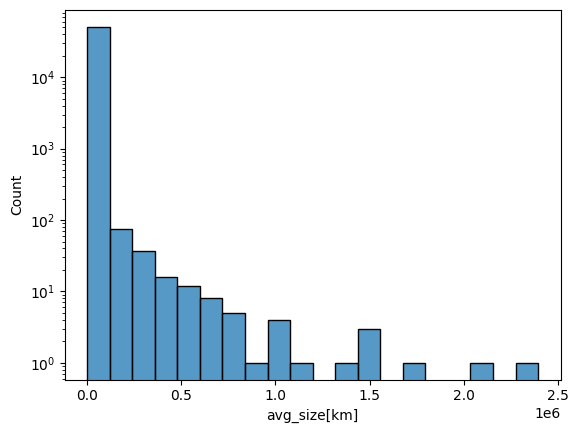

In [45]:
sns.histplot(clouds_high_res_09["avg_size[km]"], log_scale=(False, True), bins=20)


(array([ 984., 2945., 4112., 4372., 2182., 1821., 1577., 1198., 1052.,
         821.,  680.,  549.,  446.,  377.,  375.,  325.,  262.,  235.,
         219.,  163.]),
 array([ 4727.57163698,  9490.19424635, 14252.81685573, 19015.4394651 ,
        23778.06207447, 28540.68468384, 33303.30729322, 38065.92990259,
        42828.55251196, 47591.17512133, 52353.7977307 , 57116.42034008,
        61879.04294945, 66641.66555882, 71404.28816819, 76166.91077756,
        80929.53338694, 85692.15599631, 90454.77860568, 95217.40121505,
        99980.02382443]),
 <BarContainer object of 20 artists>)

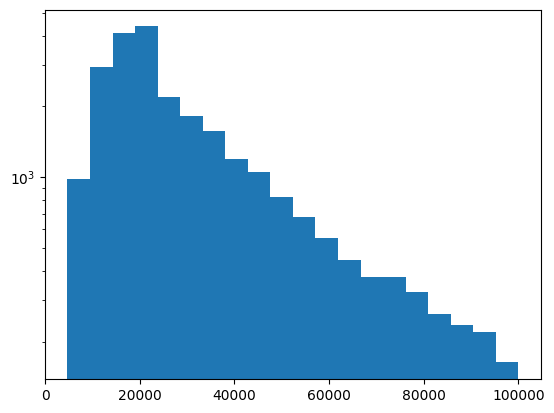

In [46]:
# clouds_model_offline_09[clouds_model_offline_09["avg_size[km]"]<0.1e7]["avg_size[km]"].hist()
plt.hist(clouds_model_offline_09[clouds_model_offline_09["avg_size[km]"]<0.01e7]["avg_size[km]"], log=True, bins=20)

## Pixel area irregular grid

In [47]:
np.arange(-36,-6+1,6)

array([-36, -30, -24, -18, -12,  -6])

In [48]:
[f"{i} to {i+6}" for i in range(-36,0,6)]

['-36 to -30',
 '-30 to -24',
 '-24 to -18',
 '-18 to -12',
 '-12 to -6',
 '-6 to 0']

In [49]:
def lat_to_pix_arr(lat_arr,lon_arr):
    """
    Convert latitude and longitude arrays to pixel indices based on the given resolution in degrees.
    
    Parameters:
    lat_arr (array-like): 2D Array of latitude values.
    lon_arr (array-like): 2D Array of longitude values.

    Returns:
    tuple: Two arrays containing the pixel indices for latitude and longitude.
    """
    res_lat = np.pad(abs(lat_arr[0,1:,0] - lat_arr[0,:-1,0]),(0,1), 'edge')  # degrees per pixel latitude direction
    res_lon = np.pad(abs(lon_arr[0,0,1:] - lon_arr[0,0,:-1]),(0,1), 'edge')   # degrees per pixel longitude direction
    return 110*110*np.outer(res_lat,res_lon)[np.newaxis,:,:]*np.cos(np.deg2rad(lat_arr)) 

test_lat_arr = np.tile(np.flip(np.linspace(-90,90,361)[:,np.newaxis],axis=0),(1,320))[np.newaxis,:,:]
test_lon_arr = np.tile(np.linspace(-120,120,320),(361,1))[np.newaxis,:,:]
result = lat_to_pix_arr(test_lat_arr,test_lon_arr)
print(test_lat_arr.shape,test_lon_arr.shape)

(1, 361, 320) (1, 361, 320)


In [50]:
result.shape

(1, 361, 320)

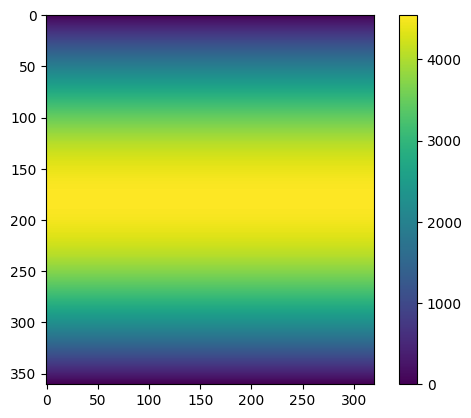

In [51]:
plt.imshow(result[0])
plt.colorbar()

In [52]:
 low_res_occ_rate

min_temp,-36,-30,-24,-18,-12,-6
Hemisphere,,,,,,
North,0.043093,0.042002,0.026807,0.021797,0.007609,0.000225
South,0.049425,0.030884,0.018008,0.014098,0.005281,0.000181
